In [1]:
import numpy as np
import pandas as pd

In [2]:
ds = pd.read_csv('AirQualityUCI.csv', sep=';', decimal=',')
ds = ds.dropna(how='all', axis=1)
ds = ds.dropna(how='all', axis=0)
ds = ds.replace(-200, np.nan)

target_col = 'C6H6(GT)'

X = ds.drop(columns=[target_col, "Date", "Time"])
y = ds[target_col].values


In [3]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')

X_clean = imputer.fit_transform(X)
y_clean = imputer.fit_transform(y.reshape(-1, 1)).flatten()


In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.25, random_state=0)

In [5]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [6]:
# --------------------------- Multiple Linear Regression ---------------------------
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [7]:
y_pred = regressor.predict(X_test)
print(y_pred)

[ 5.70362341 -0.41075445  1.51853358 ...  5.78018361  3.46281379
  5.98837875]


In [8]:
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.9774698832629686

In [9]:
# --------------------------- Decision Tree Regression ---------------------------
from sklearn.tree import DecisionTreeRegressor
regressor_tree = DecisionTreeRegressor(random_state=0)
regressor_tree.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [10]:
y_pred = regressor_tree.predict(X_test)
np.set_printoptions(precision=2)
print(np.concatenate((y_pred.reshape(len(y_pred),1), y_test.reshape(len(y_test),1)),1))

[[5.2 5.2]
 [1.6 1.6]
 [2.4 2.4]
 ...
 [5.3 5.3]
 [3.9 3.9]
 [5.8 5.8]]


In [11]:
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.9999507160042007

In [12]:
# --------------------------- Random Forest Regression ---------------------------
from sklearn.ensemble import RandomForestRegressor
regressor = RandomForestRegressor(n_estimators = 10, random_state = 0)
regressor.fit(X_train, y_train)

,n_estimators,10
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [13]:
y_pred = regressor.predict(X_test)
np.set_printoptions(precision=2)
print(np.concatenate((y_pred.reshape(len(y_pred),1), y_test.reshape(len(y_test),1)),1))

[[5.2  5.2 ]
 [1.6  1.6 ]
 [2.39 2.4 ]
 ...
 [5.3  5.3 ]
 [3.9  3.9 ]
 [5.8  5.8 ]]


In [14]:
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.9999275220836401

In [15]:
# --------------------------- Support Vector Regression ---------------------------
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X_train_scaled = sc_X.fit_transform(X_train)
X_test_scaled = sc_X.transform(X_test)
y_train_scaled = sc_y.fit_transform(y_train.reshape(-1, 1)).flatten()

In [16]:
from sklearn.svm import SVR
svr = SVR(kernel='rbf')
svr.fit(X_train_scaled, y_train_scaled)

,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [17]:
y_pred_scaled = svr.predict(X_test_scaled)
y_pred = sc_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
print(np.concatenate((y_pred.reshape(len(y_pred),1), y_test.reshape(len(y_test),1)),1))

[[4.71 5.2 ]
 [1.37 1.6 ]
 [2.56 2.4 ]
 ...
 [4.74 5.3 ]
 [3.58 3.9 ]
 [6.73 5.8 ]]


In [18]:
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.995176354258602

In [19]:
# --------------------------- Gradient Boosting Regression ---------------------------
from sklearn.ensemble import GradientBoostingRegressor
regressor = GradientBoostingRegressor(n_estimators = 18, random_state = 0, criterion='friedman_mse', learning_rate=0.1)
regressor.fit(X_train, y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,18
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [20]:
y_pred = regressor.predict(X_test)
np.set_printoptions(precision=2)
print(np.concatenate((y_pred.reshape(len(y_pred),1), y_test.reshape(len(y_test),1)),1))

[[5.82 5.2 ]
 [3.04 1.6 ]
 [3.55 2.4 ]
 ...
 [5.97 5.3 ]
 [4.98 3.9 ]
 [6.35 5.8 ]]


In [21]:
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.9738404542777345

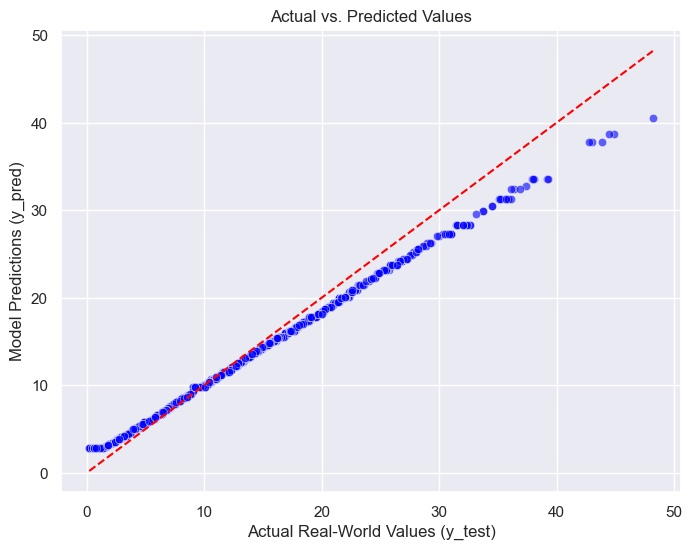

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Make the canvas look modern and set its size
sns.set_theme(style="darkgrid")
plt.figure(figsize=(8, 6))

# Create the scatter plot using Seaborn
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color="blue")

# Draw the perfect prediction diagonal line (using Matplotlib)
# We draw a red dashed line from the minimum value to the maximum value
min_val = min(min(y_test), min(y_pred))
max_val = max(max(y_test), max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.title("Actual vs. Predicted Values")
plt.xlabel("Actual Real-World Values (y_test)")
plt.ylabel("Model Predictions (y_pred)")
plt.show()

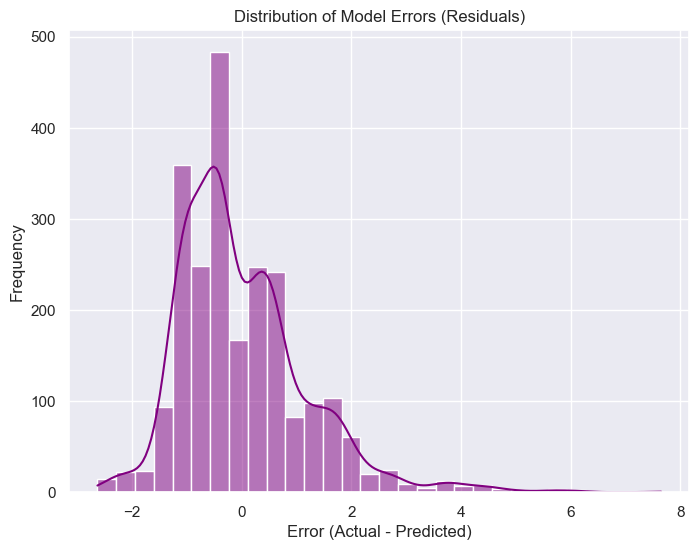

In [23]:
# Calculate the errors
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

# Create a Seaborn histogram with a smooth density curve (kde)
sns.histplot(residuals, kde=True, color="purple", bins=30)

plt.title("Distribution of Model Errors (Residuals)")
plt.xlabel("Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.show()